In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import subprocess

In [17]:
raw_vcf = "../results/05_variant_calling/raw_variants.vcf.gz"
pass_vcf = "../results/07_pass_variants/pass_variants.vcf.gz"

In [18]:
def run_command(cmd):
    result = subprocess.run(
        cmd,
        shell=True,
        capture_output=True,
        text=True
    )
    return result.stdout.strip()


# ukupan broj raw varijanti
raw_total = int(run_command(
    f'zgrep -vc "^#" {raw_vcf}'
))

# ukupan broj PASS varijanti
pass_total = int(run_command(
    f'zgrep -vc "^#" {pass_vcf}'
))

# SNP pre filtriranja
raw_snps = int(run_command(
    f'bcftools view -v snps {raw_vcf} | grep -vc "^#"'
))

# SNP posle filtriranja
pass_snps = int(run_command(
    f'bcftools view -v snps {pass_vcf} | grep -vc "^#"'
))

# INDEL pre filtriranja
raw_indels = int(run_command(
    f'bcftools view -v indels {raw_vcf} | grep -vc "^#"'
))

# INDEL posle filtriranja
pass_indels = int(run_command(
    f'bcftools view -v indels {pass_vcf} | grep -vc "^#"'
))

# broj filtriranih varijanti
filtered_out = raw_total - pass_total

# procenat filtriranih
filtered_percent = filtered_out / raw_total * 100

print("Raw variants:", raw_total)
print("PASS variants:", pass_total)
print("----------------------------")

print("Raw SNPs:", raw_snps)
print("PASS SNPs:", pass_snps)
print("----------------------------")

print("Raw INDELs:", raw_indels)
print("PASS INDELs:", pass_indels)
print("----------------------------")

print("Filtered out:", filtered_out)
print(f"Filtered percent: {filtered_percent:.2f}%")

Raw variants: 15054
PASS variants: 14697
----------------------------
Raw SNPs: 13166
PASS SNPs: 12899
----------------------------
Raw INDELs: 1892
PASS INDELs: 1798
----------------------------
Filtered out: 357
Filtered percent: 2.37%


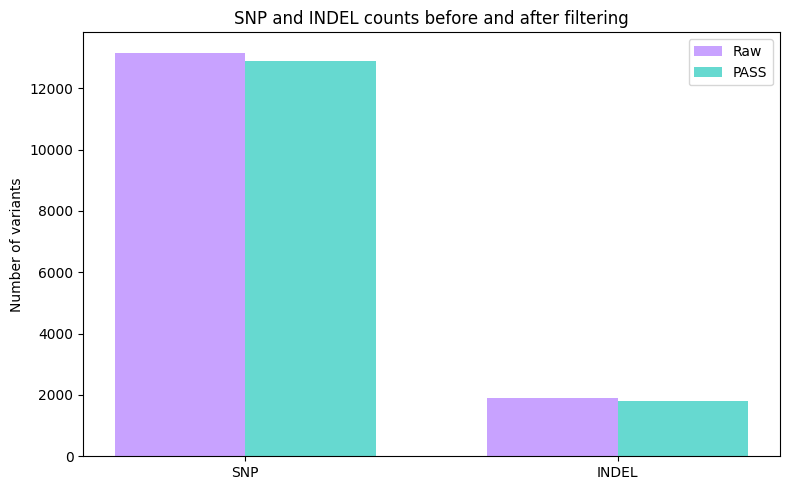

In [ ]:
labels = ["SNP", "INDEL"]

raw_counts = [raw_snps, raw_indels]
pass_counts = [pass_snps, pass_indels]

x = range(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    [i - width/2 for i in x],
    raw_counts,
    width=width,
    label="Raw",
    color="#C8A2FF"
)

plt.bar(
    [i + width/2 for i in x],
    pass_counts,
    width=width,
    label="PASS",
    color="#66D9D0"
)

plt.xticks(list(x), labels)

plt.ylabel("Number of variants")
plt.title("SNP and INDEL counts before and after filtering")

plt.legend()

plt.tight_layout()

#plt.savefig("variant_filtering_comparison.png", dpi=300)

plt.show()

In [20]:
filter_output = run_command(
    'zgrep -v "^#" ../results/06_hard_filtering/filtered_variants.vcf.gz | cut -f7 | sort | uniq -c'
)

print(filter_output)

25 FS60
      3 FS60;MQ40
     14 FS60;QD2
    190 MQ40
      4 MQ40;QD2
  14697 PASS
    117 QD2


In [21]:
filter_status_counts = {}

for line in filter_output.splitlines():
    parts = line.strip().split(maxsplit=1)

    count = int(parts[0])
    status = parts[1]

    filter_status_counts[status] = count

print(filter_status_counts)

{'FS60': 25, 'FS60;MQ40': 3, 'FS60;QD2': 14, 'MQ40': 190, 'MQ40;QD2': 4, 'PASS': 14697, 'QD2': 117}


In [22]:
filter_df = pd.DataFrame({
    "Filter status": list(filter_status_counts.keys()),
    "Count": list(filter_status_counts.values())
})

filter_df

,Filter status,Count
0,FS60,25
1,FS60;MQ40,3
2,FS60;QD2,14
3,MQ40,190
4,MQ40;QD2,4
5,PASS,14697
6,QD2,117


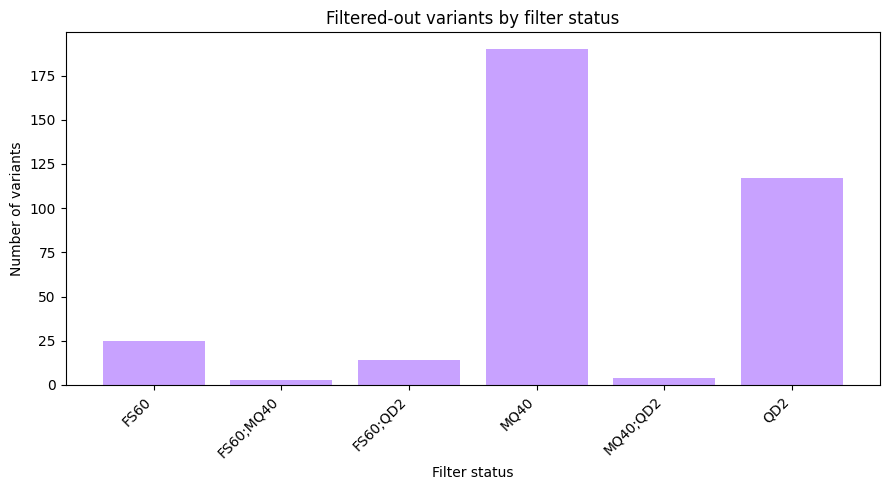

In [ ]:
# bez PASS kategorije
filtered_only_df = filter_df[filter_df["Filter status"] != "PASS"]

plt.figure(figsize=(9, 5))

plt.bar(
    filtered_only_df["Filter status"],
    filtered_only_df["Count"],
    color="#C8A2FF"
)

plt.xlabel("Filter status")
plt.ylabel("Number of variants")
plt.title("Filtered-out variants by filter status")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

#plt.savefig("variant_filter_status_counts.png", dpi=300)

plt.show()